# DSA5205 Project 2 — Real Yahoo Data Pipeline

**No synthetic data.** Downloads the latest Wikipedia S&P 500 members and real Yahoo prices; this is **survivorship-biased** and is NOT historical point-in-time index membership. Read README before interpreting results.

In [1]:
from pathlib import Path
import sys, json
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src'/'pipeline.py').exists()), None)
if ROOT is None: raise RuntimeError('Open the extracted project folder as the VS Code workspace')
sys.path.insert(0,str(ROOT))
from src.pipeline import download, run
from src.visualize import visualize
cfg=json.loads((ROOT/'config/pipeline.json').read_text())
print('Root:',ROOT,'Periods:',cfg['frequencies'])

Root: /Users/hc/Desktop/NUS DSML/DSA 5205/Project2/DSA-5205/DSA5205_Project2_Pipeline Periods: ['monthly', 'quarterly', 'semiannual']


## 1. Download and cache real market prices
The first run may take a while. For a rerun, set `REUSE_EXISTING_RAW=True` to skip downloading.

In [2]:
REUSE_EXISTING_RAW = False
if REUSE_EXISTING_RAW:
    import pandas as pd
    raw=pd.read_parquet(ROOT/'data/raw/market_data.parquet')
else:
    raw,download_status=download(cfg)
    display(download_status.status.value_counts())
print('Rows:',len(raw),'Tickers:',raw.ticker.nunique())
print('Contains synthetic:',raw.ticker.astype(str).str.startswith('SYN').any())

Downloaded/cached 25/505
Downloaded/cached 50/505
Downloaded/cached 75/505
Downloaded/cached 100/505
Downloaded/cached 125/505
Downloaded/cached 150/505
Downloaded/cached 175/505
Downloaded/cached 200/505
Downloaded/cached 225/505
Downloaded/cached 250/505
Downloaded/cached 275/505
Downloaded/cached 300/505
Downloaded/cached 325/505
Downloaded/cached 350/505
Downloaded/cached 375/505
Downloaded/cached 400/505
Downloaded/cached 425/505
Downloaded/cached 450/505
Downloaded/cached 475/505
Downloaded/cached 500/505


status
downloaded    505
Name: count, dtype: int64

Rows: 2106106 Tickers: 505
Contains synthetic: False


## 2. Generate all three holding-period datasets
Each frequency has its own decision calendar, label end date, and model-ready table.

In [3]:
results={}
for frequency in cfg['frequencies']:
    local=dict(cfg,rebalance_frequency=frequency)
    panel,screened,ready,audit=run(local,raw)
    visualize(screened,audit,ROOT/'outputs'/'figures'/frequency)
    results[frequency]=(screened,ready,audit)
    print(frequency, 'screened=',len(screened),'ready=',len(ready),'missing labels=',screened.target_forward_return.isna().sum())

monthly screened= 5760 ready= 5760 missing labels= 0
quarterly screened= 1920 ready= 1920 missing labels= 0
semiannual screened= 960 ready= 960 missing labels= 0


## 3. Quality audit
Never backfill a missing future label or reselect stocks after seeing its availability.

In [4]:
import numpy as np
from src.pipeline import FEATURES
for frequency,(screened,ready,audit) in results.items():
    print('\n',frequency)
    print('Selected per date:',screened.groupby('decision_date').ticker.nunique().value_counts().to_dict())
    print('Missing label rows:',int(screened.target_forward_return.isna().sum()))
    print('Finite ready X/Y:',np.isfinite(ready[FEATURES+['target_forward_return']].to_numpy(float)).all())
    display(audit.tail(3))


 monthly
Selected per date: {30: 192}
Missing label rows: 0
Finite ready X/Y: True


,decision_date,eligible_top300,selected,status,High_Low_available,High_Medium_available,High_High_available,Medium_Low_available,Medium_Medium_available,Medium_High_available,Low_Low_available,Low_Medium_available,Low_High_available
189,2025-10-31,300,30,ok,34,33,33,34,33,33,34,33,33
190,2025-11-28,300,30,ok,34,33,33,34,33,33,34,33,33
191,2025-12-31,300,30,ok,34,33,33,34,33,33,34,33,33



 quarterly
Selected per date: {30: 64}
Missing label rows: 0
Finite ready X/Y: True


,decision_date,eligible_top300,selected,status,High_Low_available,High_Medium_available,High_High_available,Medium_Low_available,Medium_Medium_available,Medium_High_available,Low_Low_available,Low_Medium_available,Low_High_available
61,2025-06-30,300,30,ok,34,33,33,34,33,33,34,33,33
62,2025-09-30,300,30,ok,34,33,33,34,33,33,34,33,33
63,2025-12-31,300,30,ok,34,33,33,34,33,33,34,33,33



 semiannual
Selected per date: {30: 32}
Missing label rows: 0
Finite ready X/Y: True


,decision_date,eligible_top300,selected,status,High_Low_available,High_Medium_available,High_High_available,Medium_Low_available,Medium_Medium_available,Medium_High_available,Low_Low_available,Low_Medium_available,Low_High_available
29,2024-12-31,300,30,ok,34,33,33,34,33,33,34,33,33
30,2025-06-30,300,30,ok,34,33,33,34,33,33,34,33,33
31,2025-12-31,300,30,ok,34,33,33,34,33,33,34,33,33


## 4. Visual inspection

monthly


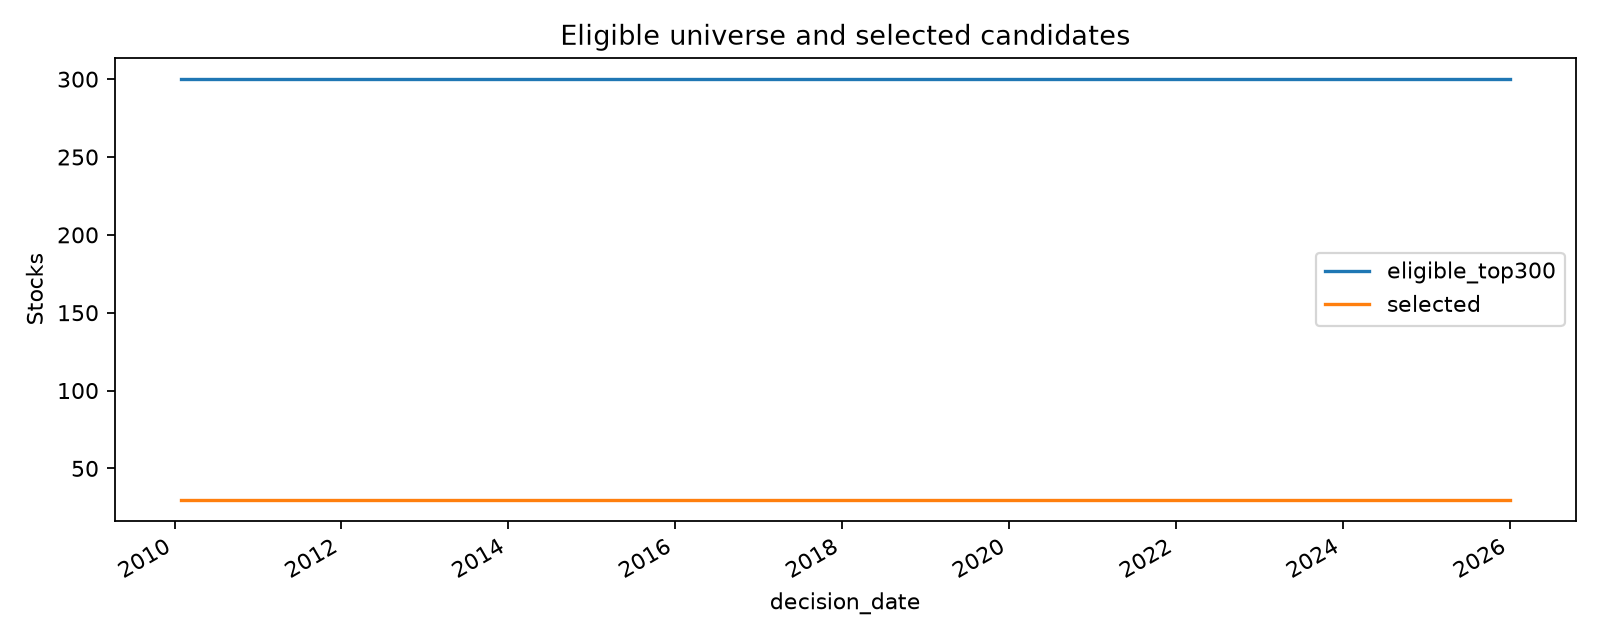

quarterly


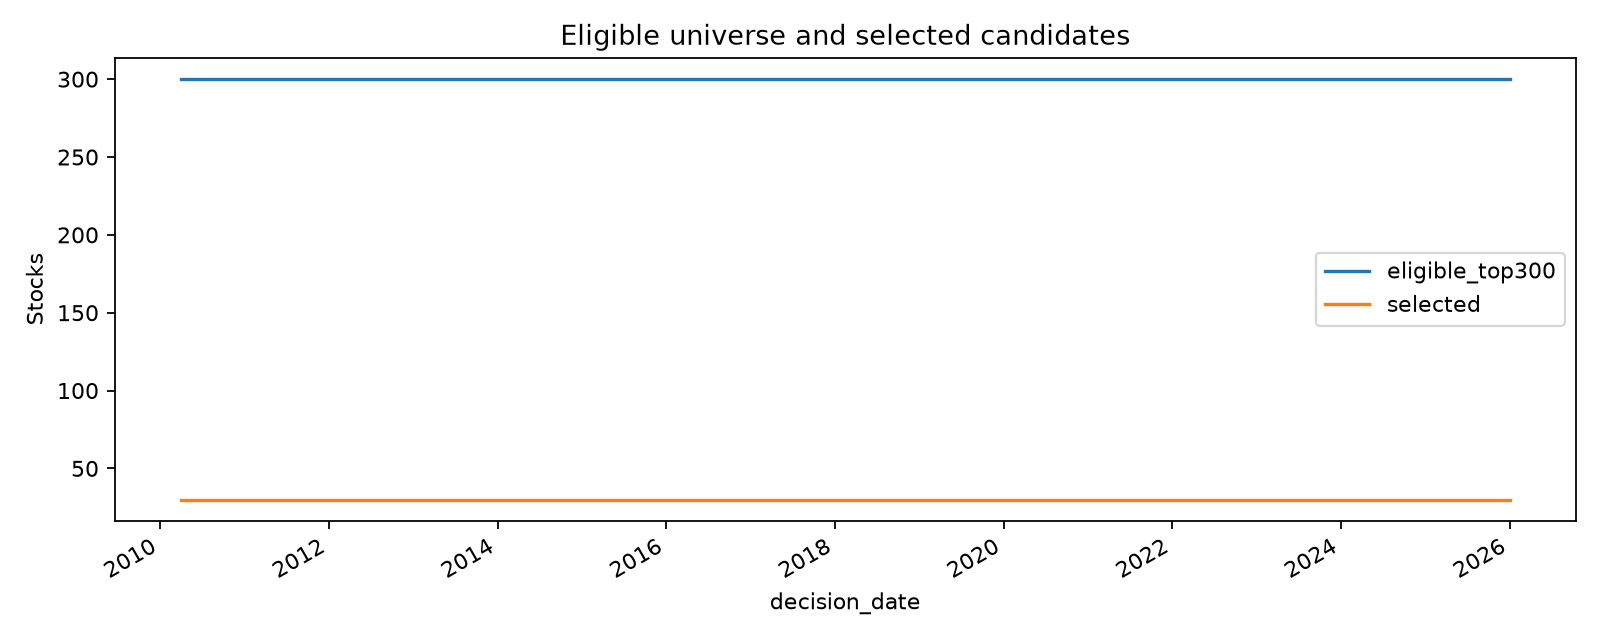

semiannual


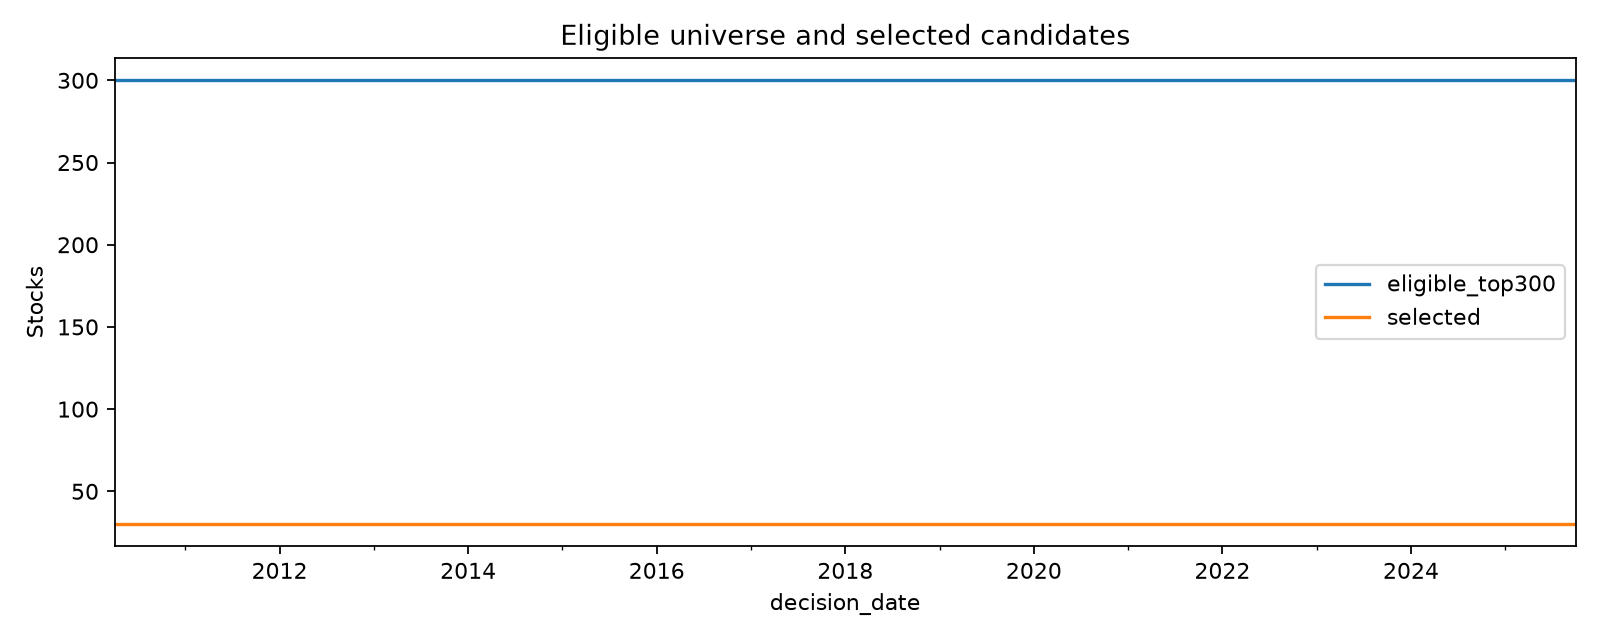

In [5]:
from IPython.display import display, Image
for f in cfg['frequencies']:
    print(f)
    display(Image(filename=str(ROOT/'outputs'/'figures'/f/'screening_coverage.png')))

## 5. Handoff
Team members use `data/processed_ready/{frequency}/model_ready.parquet`, `feature_columns.json`, and **`target_forward_return`**. Do not use future labels or future ETF returns as X. See `02_unified_models.ipynb`.